In [1]:
# Settings and constants
from pathlib import Path
from functools import lru_cache
import string
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator
from scipy.constants import Avogadro, R, pi
from numpy.polynomial import Polynomial

DATA_FOLDER = Path("Data")
MAGEMIN_FOLDER = Path(r"C:\Users\anast\.julia\packages\MAGEMinApp\dKlgF\output")
CONSTANTS_FILE = DATA_FOLDER / "melting_constants.xlsx"
FIGURE_FOLDER = DATA_FOLDER / "figures" / "Chapter4_melting"
FIGURE_FOLDER.mkdir(parents=True, exist_ok=True)

PM_FILES = {
    (1.5, "batch"): "15_batch_final_ig.csv", (1.5, "continuous"): "1.5_CONT_1%_ig.csv", (1.5, "fractional"): "15_frac_final_ig.csv",
    (3.0, "batch"): "PM_BATCH_3GPA_ig.csv", (3.0, "continuous"): "3_CONT_1%_ig.csv", (3.0, "fractional"): "PM_FRAC_3GPA_ig.csv"}
KR_FILES = {
    (10.0, "batch"): "KR_10_batch_final_ig_ig.csv", (10.0, "continuous"): "KR_1_CONT_1%_ig.csv", (10.0, "fractional"): "KR_10_frac_final_ig_ig.csv",
    (15.0, "batch"): "KR_15_batch_final_ig.csv", (15.0, "continuous"): "KR_1.5_CONT_1%_ig.csv", (15.0, "fractional"): "KR_15_frac_final_ig.csv",
    (30.0, "batch"): "KR_30_batch_final_final_ig.csv", (30.0, "continuous"): "KR_3_CONT_1%_ig.csv", (30.0, "fractional"): "KR_30_frac_final_final_ig.csv",
    (40.0, "batch"): "KR_40_batch_final_ig.csv", (40.0, "continuous"): "KR_4_CONT_1%_ig.csv", (40.0, "fractional"): "KR_40_frac_final_ig.csv"}

PRESSURES, STYLES = (1.5, 3.0), ("batch", "continuous", "fractional")
FACIES = {1.5: "spinel", 3.0: "garnet"}
FP, CPX_TOL = 0.01, 1e-4
F_GRID = np.round(np.arange(0.0, 0.2001, 0.005), 3)
F_SHOW = np.array([0.0, 0.05, 0.1, 0.15, 0.195])
RUNS = {"modal": ("modal", "constant"), "nonmodal_constant": ("non_modal", "constant"), "nonmodal_variable": ("non_modal", "variable")}
LAMBDA_MAX = 3
LAMBDA_TERMS = [f"lambda_{i}" for i in range(LAMBDA_MAX + 1)]
RADIUS_TICKS = np.array([1.15, 1.1, 1.05, 1.0])

FIG_RC = {"font.family": "serif", "font.serif": ["Computer Modern Roman", "CMU Serif", "DejaVu Serif"], "mathtext.fontset": "cm",
          "font.size": 12, "axes.labelsize": 15, "xtick.labelsize": 11, "ytick.labelsize": 11, "legend.fontsize": 12,
          "figure.dpi": 140, "savefig.dpi": 300}
THESIS_RC = {"font.family": "serif", "font.serif": ["Times New Roman", "Times", "DejaVu Serif"], "mathtext.fontset": "stix",
             "font.size": 11, "axes.labelsize": 12, "axes.titlesize": 12, "xtick.labelsize": 10, "ytick.labelsize": 10,
             "legend.fontsize": 10, "figure.titlesize": 13, "axes.facecolor": "white", "figure.facecolor": "white",
             "axes.edgecolor": "0.35", "axes.linewidth": 0.9, "xtick.direction": "out", "ytick.direction": "out",
             "xtick.major.size": 4.0, "ytick.major.size": 4.0, "xtick.major.width": 0.8, "ytick.major.width": 0.8,
             "grid.color": "0.90", "grid.linewidth": 0.5}
PHASE_COLOURS = {"ol": "#27B7B0", "opx": "#4C5BE8", "cpx": "#F28E2B", "spl": "#333333", "g": "#E75A9D"}
PHASE_LABELS = {"ol": "Olivine", "opx": "Orthopyroxene", "cpx": "Clinopyroxene", "spl": "Spinel", "g": "Garnet"}
LINESTYLES = {"batch": "-", "continuous": "--", "fractional": ":"}
STYLE_LABELS = {"batch": "Batch melting", "continuous": "Continuous melting", "fractional": "Fractional melting"}
MODEL_COLOURS = {"spinel": "#3F73F1", "garnet": "#B24FE3"}
RUN_COLORS = {"modal": "#4D98C0", "nonmodal_constant": "#DC6199", "nonmodal_variable": "#8863B9"}
RUN_LABELS = {"modal": r"Modal, constant $K$", "nonmodal_constant": r"Non-modal, constant $K$",
              "nonmodal_variable": r"Non-modal, variable $K$"}


def save_figure(fig, name, pad=0.1, png=False):
    fig.savefig(FIGURE_FOLDER / f"{name}.pdf", bbox_inches="tight", pad_inches=pad)
    if png:
        fig.savefig(FIGURE_FOLDER / f"{name}.png", dpi=600, bbox_inches="tight", pad_inches=pad)
    plt.show()


constants = pd.read_excel(CONSTANTS_FILE, sheet_name=None)
ree_df = constants["REE"].iloc[:, :5]
REE = ree_df["Element"].astype(str).tolist()
RADII = ree_df["Ionic radius "].to_numpy(float)
CI_ARR = ree_df["CI chondrite (ppm)"].to_numpy(float)
SOURCE_PM = constants["Sources_REE"].set_index("Element").loc[REE, "PM_PO14 (ppm)"].to_numpy(float)
PHASES = {"Olivine": "ol_solid", "Orthopyroxene": "opx_solid", "Clinopyroxene": "cpx_solid", "Spinel": "spl_solid", "Garnet": "g_solid"}
D_CONST = {phase: constants["Partition_Coef"].set_index("REE").loc[REE, phase].to_numpy(float) for phase in PHASES}
OXIDES = constants["Bulk_oxides"]["Oxide"].dropna().astype(str).tolist()

In [2]:
# MAGEMin melting paths
def load_magemin_csv(filename, style):
    raw = pd.read_csv(filename)
    system = raw.loc[raw["phase"].eq("system")].drop_duplicates("point[#]").set_index("point[#]")
    wt = raw.loc[~raw["phase"].eq("system")].pivot_table(index="point[#]", columns="phase", values="mode[wt%]",
                                                         aggfunc="sum", fill_value=0.0) / 100
    data = system[["P[GPa]", "T[°C]"]].join(wt.add_prefix("wt_")).sort_index()
    get = lambda col: data.get(col, pd.Series(0.0, index=data.index)).to_numpy(float)
    L = get("wt_liq")
    F, R_before, Rm = [], [], 1.0
    for Lw in L:
        R_before.append(Rm)
        if style == "fractional":
            Rm = Rm * (1.0 - Lw)
            F.append(1.0 - Rm)
        elif style == "continuous":
            if Lw > FP:
                Rm = Rm * (1.0 - (Lw - FP) / (1.0 - FP))
            F.append((1.0 - Rm) + (FP if Lw > FP else Lw) * Rm)
        else:
            F.append(Lw)
    out = pd.DataFrame({"P_GPa": data["P[GPa]"].to_numpy(float), "T_C": data["T[°C]"].to_numpy(float), "F": np.asarray(F)})
    solid, R_before = 1.0 - L, np.asarray(R_before)
    for phase in PHASE_COLOURS:
        current = get("wt_cpx") + get("wt_pig") if phase == "cpx" else get(f"wt_{phase}")
        out[phase] = R_before * current
        out[f"{phase}_solid"] = np.divide(current, solid, out=np.zeros_like(current), where=solid > 0)
    liquid = raw.loc[raw["phase"].eq("liq")].drop_duplicates("point[#]").set_index("point[#]")
    for oxide in OXIDES:
        if f"{oxide}[wt%]" in system.columns:
            bulk = system[f"{oxide}[wt%]"].reindex(data.index).to_numpy(float) / 100
            melt = np.nan_to_num(liquid[f"{oxide}[wt%]"].reindex(data.index).to_numpy(float) / 100, nan=0.0)
            out[oxide] = np.divide(bulk - L * melt, 1.0 - L, out=np.full_like(bulk, np.nan), where=(1.0 - L) > 1e-12)
    return out


def load_paths(files, key):
    return pd.concat([load_magemin_csv(MAGEMIN_FOLDER / name, style).assign(**{key: P, "style": style})
                      for (P, style), name in files.items()], ignore_index=True)


melting_paths = load_paths(PM_FILES, "P_GPa_run")
kr4003 = load_paths(KR_FILES, "P_kbar")

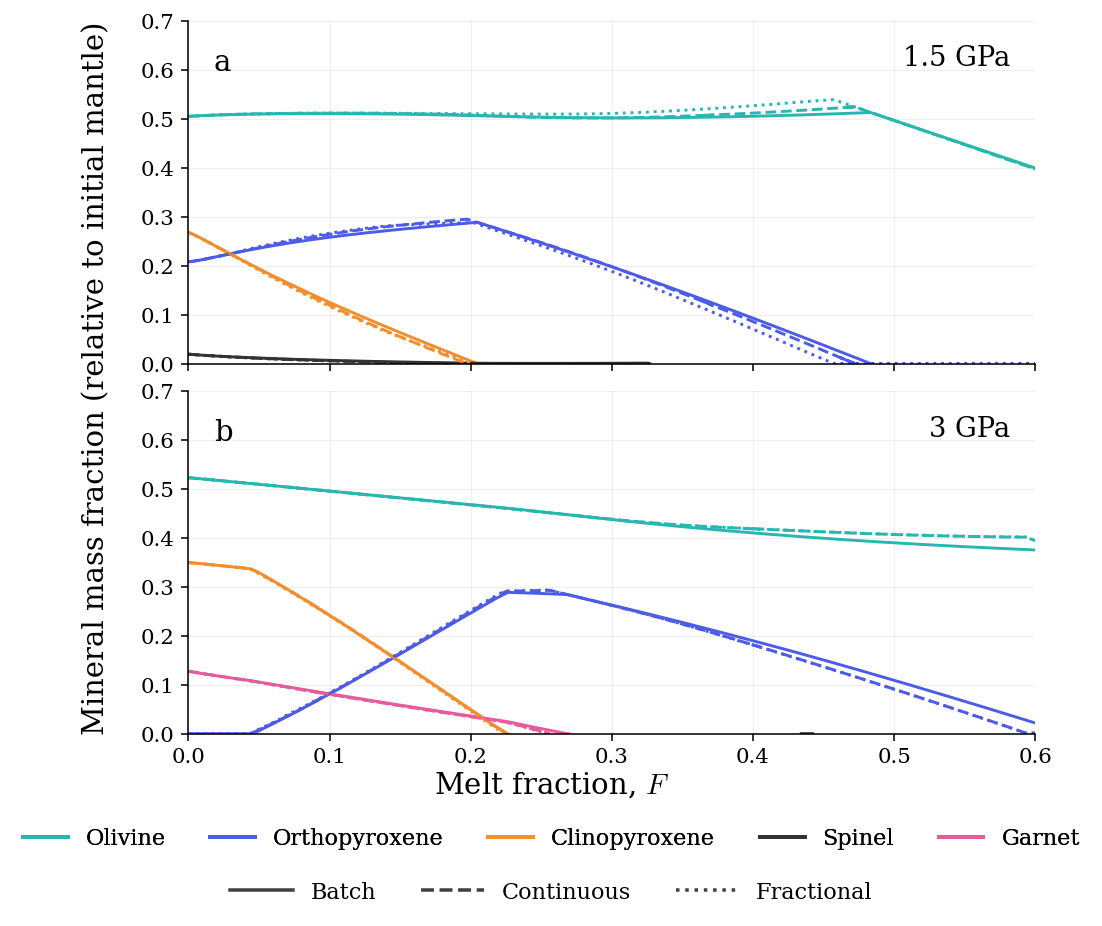

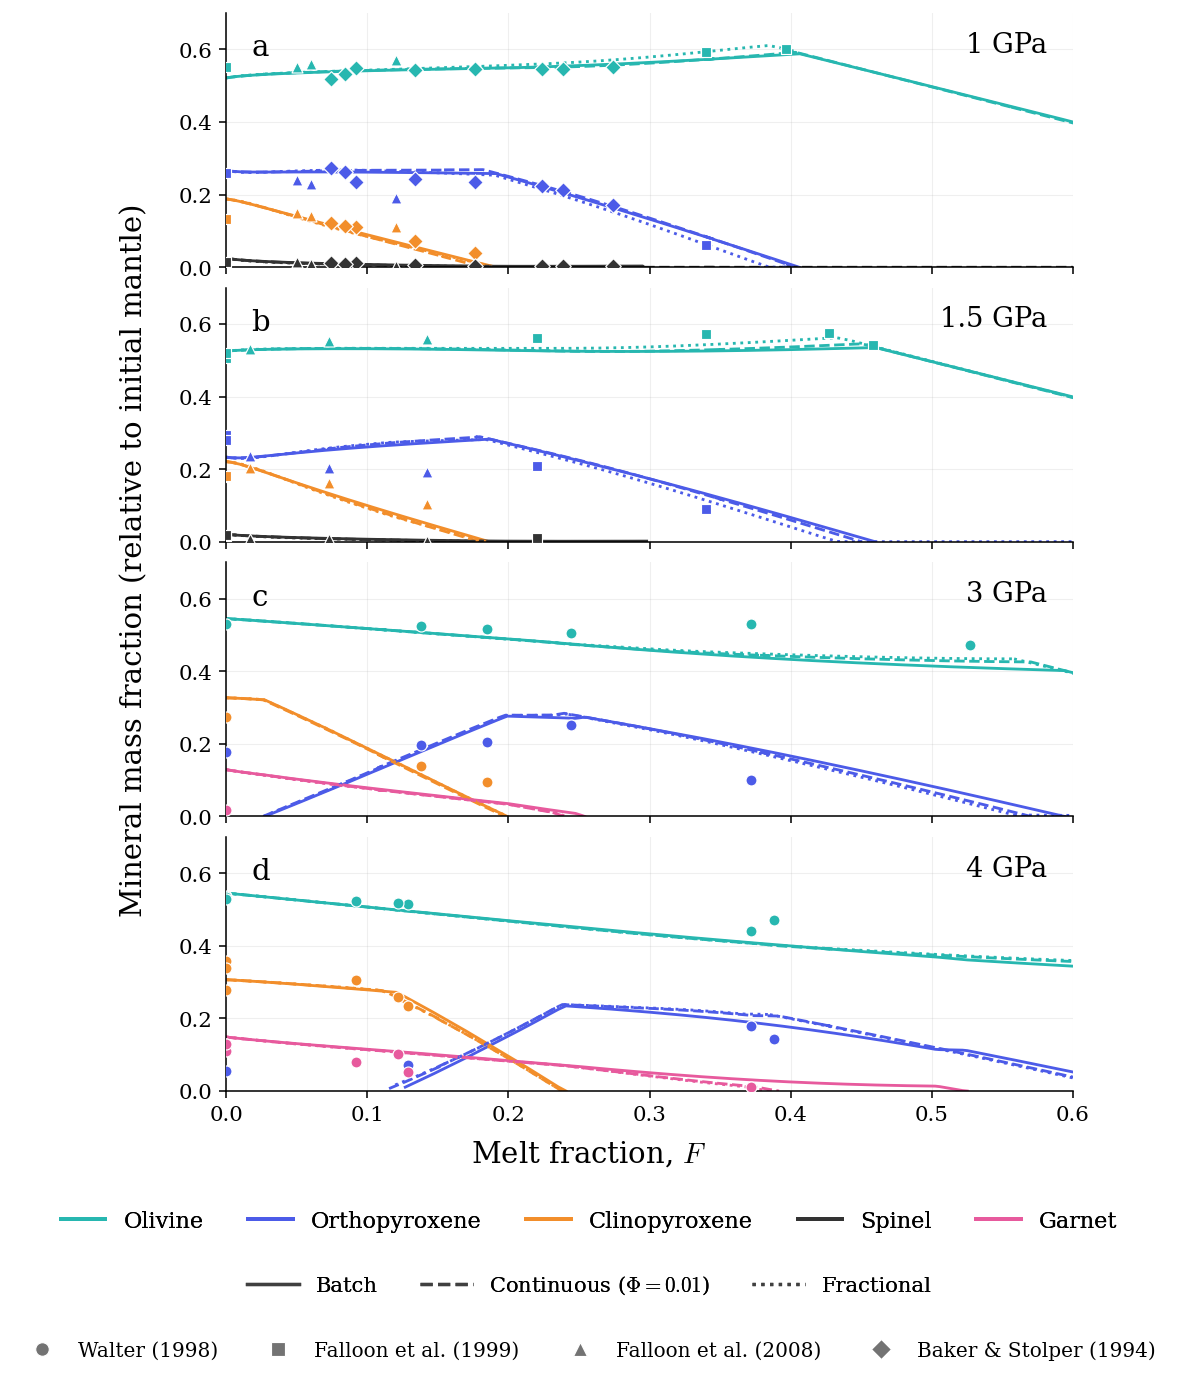

In [3]:
# Figures 4.4 and 4.5
def phase_curve_for_plot(df, phase, used_up=0.002, min_gap=0.1, max_jump=0.1):
    work = df.sort_values("T_C").reset_index(drop=True)
    x, y = work["F"].to_numpy(float), work[phase].to_numpy(float)
    good = np.isfinite(x) & np.isfinite(y)
    present = good & (y > CPX_TOL)
    if not present.any():
        return x, np.full_like(y, np.nan)
    start, last = np.flatnonzero(present)[[0, -1]]
    y_plot = np.full_like(y, np.nan, dtype=float)
    y_plot[start:last + 1] = np.where(good[start:last + 1], y[start:last + 1], np.nan)
    if last + 1 < len(y) and np.isfinite(x[last + 1]):
        y_plot[last + 1] = 0.0
    keep, seen = np.zeros(len(x), dtype=bool), []
    for i in np.flatnonzero(np.isfinite(x) & np.isfinite(y_plot))[::-1]:
        if not any(abs(x[i] - previous) <= 1e-10 for previous in seen):
            keep[i] = True
            seen.append(x[i])
    y_plot[~keep] = np.nan
    on = np.flatnonzero((y > used_up) & (np.arange(len(y)) >= np.nanargmax(np.where(good, y, np.nan))))
    back = np.flatnonzero((np.diff(on) > 1) & (x[on[1:]] - x[on[:-1] + 1] > min_gap))
    drawn = np.flatnonzero(np.isfinite(y_plot))
    jump = np.flatnonzero((np.diff(drawn) > 1) & (np.abs(np.diff(y_plot[drawn])) > max_jump))
    cut = min([len(y)] + [on[k + 1] for k in back[:1]] + [drawn[k + 1] for k in jump[:1]])
    y_plot[cut:] = np.nan
    return x, y_plot


def format_axis(ax, n, label):
    ax.text(0.03, 0.92, string.ascii_lowercase[n], transform=ax.transAxes, fontsize=15, va="top")
    ax.text(0.97, 0.93, label, transform=ax.transAxes, fontsize=14, ha="right", va="top")
    ax.set(xlim=(0, 0.60), ylim=(0, 0.70))
    ax.grid(True, alpha=0.20, linewidth=0.55)
    ax.spines[["top", "right"]].set_visible(False)


def plot_modes(ax, model, lw, skip_spl=False):
    for style in STYLES:
        m = model[model["style"].eq(style)]
        for phase in PHASE_COLOURS:
            if (phase == "spl" and skip_spl) or m.empty or m[phase].max() <= CPX_TOL:
                continue
            ax.plot(*phase_curve_for_plot(m, phase), color=PHASE_COLOURS[phase], linestyle=LINESTYLES[style], linewidth=lw)


phase_handles = [Line2D([], [], color=PHASE_COLOURS[p], lw=2.0, label=PHASE_LABELS[p]) for p in PHASE_COLOURS]

with plt.rc_context(FIG_RC):
    fig, axes = plt.subplots(2, 1, figsize=(7.2, 6.7), sharex=True, sharey=True)
    for n, (ax, P) in enumerate(zip(axes, PRESSURES)):
        plot_modes(ax, melting_paths[np.isclose(melting_paths["P_GPa"], P)], lw=1.5)
        format_axis(ax, n, f"{P:g} GPa")
    fig.supxlabel("Melt fraction, $F$", y=0.15, fontsize=15)
    fig.supylabel("Mineral mass fraction (relative to initial mantle)", x=0.035,y=0.60, fontsize=15)
    fig.add_artist(fig.legend(handles=phase_handles, loc="lower center", bbox_to_anchor=(0.5, 0.075), ncol=5, frameon=False,
                              fontsize=11.5, handlelength=2.0))
    fig.legend(handles=[Line2D([], [], color="0.25", lw=1.8, linestyle=LINESTYLES[s], label=s.capitalize()) for s in STYLES],
               loc="lower center", bbox_to_anchor=(0.5, 0.018), ncol=3, frameon=False, fontsize=11.5, handlelength=2.8)
    fig.subplots_adjust(left=0.14, right=0.98, top=0.98, bottom=0.22, hspace=0.08)
    save_figure(fig, "PM_melting_styles")

SOURCE_MARKERS = {"Walter": "o", "Falloon": "s", "Falloon 2008": "^", "Baker & Stolper": "D"}
SOURCE_LABELS = {"Walter": "Walter (1998)", "Falloon": "Falloon et al. (1999)", "Falloon 2008": "Falloon et al. (2008)",
                 "Baker & Stolper": "Baker & Stolper (1994)"}
experimental = constants["Experimental_modes"]
exp_P = pd.to_numeric(experimental["P_kbar"], errors="coerce")
with plt.rc_context(FIG_RC):
    fig, axes = plt.subplots(4, 1, figsize=(7.2, 10.0), sharex=True, sharey=True)
    plotted = set()
    for n, (ax, P) in enumerate(zip(axes, [10.0, 15.0, 30.0, 40.0])):
        plot_modes(ax, kr4003[np.isclose(pd.to_numeric(kr4003["P_kbar"], errors="coerce"), P)], lw=1.45, skip_spl=P > 20)
        for _, row in experimental.loc[np.isclose(exp_P, P) | (np.isclose(exp_P, 45.0) & np.isclose(P, 40.0))].iterrows():
            if row["source"] not in SOURCE_MARKERS:
                continue
            plotted.add(row["source"])
            for phase in PHASE_COLOURS:
                if (phase == "spl" and P > 20) or phase not in row.index:
                    continue
                value, F = pd.to_numeric(row[phase], errors="coerce"), pd.to_numeric(row["liq"], errors="coerce")
                if pd.notna(value) and pd.notna(F) and value > 0:
                    ax.scatter(F, value, s=32, marker=SOURCE_MARKERS[row["source"]], facecolor=PHASE_COLOURS[phase],
                               edgecolor="white", linewidth=0.6, zorder=5)
        format_axis(ax, n, f"{P / 10:g} GPa")
    fig.supxlabel("Melt fraction, $F$", y=0.165, fontsize=15)
    fig.supylabel("Mineral mass fraction (relative to initial mantle)", x=0.035, y=0.60, fontsize=15)
    fig.add_artist(fig.legend(handles=phase_handles, loc="lower center", bbox_to_anchor=(0.5, 0.105), ncol=5, frameon=False,
                              fontsize=11.5, handlelength=2.0))
    style_labels = {"batch": "Batch", "continuous": r"Continuous ($\Phi=0.01$)", "fractional": "Fractional"}
    fig.add_artist(fig.legend(handles=[Line2D([], [], color="0.25", linestyle=LINESTYLES[s], lw=1.7, label=style_labels[s]) for s in STYLES],
                              loc="lower center", bbox_to_anchor=(0.5, 0.06), ncol=3, frameon=False, fontsize=10.8, handlelength=2.5))
    handles = [Line2D([], [], marker=SOURCE_MARKERS[s], linestyle="None", markerfacecolor="0.45", markeredgecolor="white",
                      markeredgewidth=0.6, markersize=7, label=SOURCE_LABELS[s]) for s in SOURCE_MARKERS if s in plotted]
    if handles:
        fig.legend(handles=handles, loc="lower center", bbox_to_anchor=(0.5, 0.015), ncol=len(handles), frameon=False, fontsize=10.3)
    fig.subplots_adjust(left=0.14, right=0.98, top=0.99, bottom=0.22, hspace=0.08)
    save_figure(fig, "KR4003_validation")

1.5 GPa | solidus modes: Olivine 0.5048, Orthopyroxene 0.2080, Clinopyroxene 0.2680, Spinel 0.0192, Garnet 0.0000 | cpx-out F: batch 0.204, continuous 0.197, fractional 0.200 | batch: spl-out 0.327, grt-out nan, opx-in nan
3 GPa | solidus modes: Olivine 0.5229, Orthopyroxene 0.0000, Clinopyroxene 0.3495, Spinel 0.0000, Garnet 0.1276 | cpx-out F: batch 0.218, continuous 0.223, fractional 0.221 | batch: spl-out 0.442, grt-out 0.269, opx-in 0.049


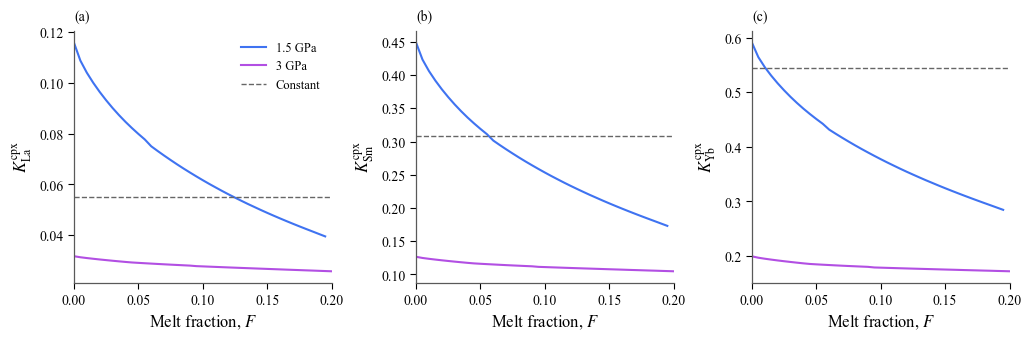

In [4]:
# Table 4.3, variable partition coefficients and Figure 4.3
def prepare_mode_path(df):
    df = df.sort_values("T_C").reset_index(drop=True)
    present = (df["cpx_solid"] >= CPX_TOL).to_numpy()
    out = np.flatnonzero(present[:-1] & ~present[1:])
    df = df.iloc[:out[0] + 1 if len(out) else len(df)]
    keep = [0]
    for i in range(1, len(df)):
        dF = df.loc[i, "F"] - df.loc[keep[-1], "F"]
        if dF > 1e-10:
            keep.append(i)
        elif abs(dF) <= 1e-10:
            keep[-1] = i
    return df.loc[keep].reset_index(drop=True)


def row_to_mode(row):
    return {phase: float(row[col]) for phase, col in PHASES.items()}


MODE_PATHS = {(float(P), style): prepare_mode_path(df) for (P, style), df in melting_paths.groupby(["P_GPa", "style"])}
START_MODES = {P: row_to_mode(MODE_PATHS[P, "batch"].iloc[0]) for P in PRESSURES}


def phase_change_F(df, col, appear=False):
    df = df.sort_values("T_C")
    on = (df[col] >= CPX_TOL).to_numpy()
    i = np.flatnonzero(on[1:] & ~on[:-1] if appear else on[:-1] & ~on[1:])
    return df["F"].iloc[i[0] + 1] if len(i) else np.nan


for P in PRESSURES:
    batch = melting_paths[np.isclose(melting_paths["P_GPa"], P) & melting_paths["style"].eq("batch")]
    print(f"{P:g} GPa | solidus modes: " + ", ".join(f"{ph} {v:.4f}" for ph, v in START_MODES[P].items())
          + " | cpx-out F: " + ", ".join(f"{s} {MODE_PATHS[P, s]['F'].max():.3f}" for s in STYLES)
          + f" | batch: spl-out {phase_change_F(batch, 'spl_solid'):.3f}, grt-out {phase_change_F(batch, 'g_solid'):.3f}, "
          f"opx-in {phase_change_F(batch, 'opx_solid', appear=True):.3f}")


@lru_cache(maxsize=None)
def mode_at(P, style, F):
    path = MODE_PATHS[P, style]
    if F > path["F"].max() + 1e-10:
        return None
    if F <= path["F"].iloc[0]:
        return row_to_mode(path.iloc[0])
    return {phase: float(np.interp(F, path["F"], path[col])) for phase, col in PHASES.items()}


def T_at(P, style, F):
    path = MODE_PATHS[P, style]
    return float(np.interp(F, path["F"], path["T_C"])) + 273.15


LS_RI = np.array([1.16, 1.143, 1.126, 1.109, 1.079, 1.066, 1.053, 1.04, 1.027, 1.015, 1.004, 0.994, 0.985, 0.977])


def lattice_strain(D0, E, r0, T_K):
    term = r0 / 2 * (LS_RI - r0) ** 2 + (LS_RI - r0) ** 3 / 3
    return D0 * np.exp(-4 * pi * E * Avogadro / R / T_K * term * 1e-21)


def al_select(spl_coef, grt_coef, k, mode):
    spl, grt = mode["Spinel"], mode["Garnet"]
    w = grt / (spl + grt) if spl + grt > 0 else 0.0
    return (1 - w) * (np.array(spl_coef) @ k) + w * (np.array(grt_coef) @ k)


def D_ree_variable(P, T_K, F, mode):
    k = np.kron([F, 1.0], [T_K, 1.0])
    D = {"Spinel": D_CONST["Spinel"]}
    X_Al = al_select([-1.166e-4, 1.628e-1, 6.632e-5, -1.001e-1], [4.717e-6, -7.203e-3, -2.738e-6, 1.069e-2], k, mode)
    Mg_num = al_select([4.746e-5, -2.941e-2, 4.057e-6, 8.990e-1], [-6.102e-7, 6.992e-2, 1.893e-5, 8.604e-1], k, mode)
    D["Olivine"] = lattice_strain(np.exp(-0.44 - 0.18 * P + 123.75 * X_Al - 1.49 * Mg_num), 298.0, 0.809, T_K)
    X_Al_T = al_select([-8.137e-4, 1.060, 1.786e-4, -1.333e-1], [1.070e-3, -2.114, -5.671e-4, 1.196], k, mode)
    X_Ca_M2 = al_select([-1.097e-3, 1.747, 2.037e-4, -2.385e-1], [-1.862e-4, 2.338e-1, 1.426e-4, -1.559e-1], k, mode)
    X_Mg_M2 = al_select([1.274e-3, -1.969, -2.631e-4, 1.242], [1.386e-4, -6.299e-2, -1.497e-4, 1.063], k, mode)
    X_Ti = al_select([2.087e-4, -4.405e-1, 1.498e-5, 1.156e-2], [1.225e-4, -3.037e-1, -2.206e-5, 8.261e-2], k, mode)
    r0 = 0.693 + 0.432 * X_Ca_M2 + 0.228 * X_Mg_M2
    D["Orthopyroxene"] = lattice_strain(np.exp(-5.37 + 3.87e4 / R / T_K + 3.54 * X_Al_T + 3.56 * X_Ca_M2 - 0.84 * X_Ti),
                                        (1.85 * r0 - 1.37 - 0.53 * X_Ca_M2) * 1e3, r0, T_K)
    X_Mg_M2 = al_select([3.000e-3, -4.675, 1.270e-3, -1.688], [-5.157e-6, 2.422e-1, 2.201e-4, 1.312e-1], k, mode)
    X_Al2O3 = al_select([3.055e-4, -6.387e-1, -1.313e-4, 3.259e-1], [1.264e-4, -2.287e-1, -1.855e-4, 4.052e-1], k, mode)
    X_SiO2 = al_select([5.050e-4, -8.057e-1, -3.469e-4, 1.065], [8.899e-8, 2.692e-2, -1.265e-4, 6.800e-1], k, mode)
    melt_factor = X_SiO2 ** 2.54 * 2 * X_Al2O3 / X_SiO2 * 1.99
    D["Clinopyroxene"] = lattice_strain(np.exp(-2.07 + 0.52e4 / T_K), 238.0, 1.036 - 0.08 * X_Mg_M2, T_K) * melt_factor
    X_Ca = np.array([4.516e-5, -2.685e-1, -2.325e-4, 7.989e-1]) @ k
    r0 = 0.785 + 0.153 * X_Ca
    D["Garnet"] = lattice_strain(np.exp(-2.01 + (9.03e4 - 93.02 * P * (37.78 - P)) / R / T_K - 1.04 * X_Ca),
                                 (-1.67 + 2.35 * r0) * 1e3, r0, T_K)
    return D


@lru_cache(maxsize=None)
def D_at(P, style, F, D_mode):
    if D_mode == "constant":
        return D_CONST
    return D_ree_variable(P, T_at(P, style, F), F, mode_at(P, style, F) or mode_at(P, style, 0.0))


def start_D(P, D_mode):
    return D_CONST if D_mode == "constant" else D_ree_variable(P, T_at(P, "batch", 0.0), 0.0, START_MODES[P])


variable_K_df = pd.DataFrame([{"P_GPa": P, "style": style, "F": float(F), "T_C": T_at(P, style, F) - 273.15, "phase": ph,
                               **dict(zip(REE, D_at(P, style, float(F), "variable")[ph]))}
                              for P in PRESSURES for style in STYLES
                              for F in F_GRID[F_GRID <= MODE_PATHS[P, style]["F"].max() + 1e-10] for ph in PHASES])

with plt.rc_context(THESIS_RC):
    fig, axes = plt.subplots(1, 3, figsize=(3.4 * 3, 3.3), constrained_layout=True)
    for ax, el, letter in zip(axes, ("La", "Sm", "Yb"), string.ascii_lowercase):
        for P in PRESSURES:
            sub = variable_K_df[(variable_K_df["P_GPa"] == P) & (variable_K_df["style"] == "continuous")
                                & (variable_K_df["phase"] == "Clinopyroxene")]
            ax.plot(sub["F"], sub[el], color=MODEL_COLOURS[FACIES[P]], lw=1.5, label=f"{P:g} GPa")
        ax.axhline(D_CONST["Clinopyroxene"][REE.index(el)], color="0.4", lw=1.0, ls="--", label="Constant")
        ax.set_xlim(0, 0.2)
        ax.set_xlabel("Melt fraction, $F$")
        ax.set_ylabel(f"$K^{{\\mathrm{{cpx}}}}_{{\\mathrm{{{el}}}}}$")
        ax.spines[["top", "right"]].set_visible(False)
        ax.text(0.0, 1.03, f"({letter})", transform=ax.transAxes, ha="left", va="bottom", fontsize=10)
    axes[0].legend(frameon=False, fontsize=9)
    save_figure(fig, "K_cpx_variable_vs_constant_continuous", png=True)

In [5]:
# Residual clinopyroxene REE and lambda coefficients
def bulk_D(mode, D):
    return sum(mode[ph] * D[ph] for ph in PHASES)


def reaction_p(m0, m1, f):
    return {ph: (m0[ph] - (1 - f) * m1[ph]) / f for ph in PHASES}


def residue_step(D0, Pr, f, phi):
    D_eff, P_eff = phi + (1 - phi) * D0, phi + (1 - phi) * Pr
    with np.errstate(divide="ignore", invalid="ignore"):
        base = 1 - P_eff * f / D_eff
        step = np.where(np.abs(P_eff) < 1e-12, np.exp(-f / D_eff), np.power(base, 1 / P_eff)) / (1 - f)
    return np.where((D_eff > 0) & (base > 0), step, np.nan)


def cpx_ratio(P, style, F, run):
    melting_mode, D_mode = RUNS[run]
    path = MODE_PATHS[P, style]
    nan = np.full(len(REE), np.nan)
    if F > path["F"].max() + 1e-10:
        return nan
    if np.isclose(F, 0.0):
        D0 = start_D(P, D_mode)
        return D0["Clinopyroxene"] / bulk_D(START_MODES[P], D0)
    if melting_mode == "modal":
        D0, Dcpx = bulk_D(START_MODES[P], D_CONST), D_CONST["Clinopyroxene"]
        if style == "batch" or (style == "continuous" and F <= FP):
            return Dcpx / (F + (1 - F) * D0)
        if style == "fractional":
            return Dcpx / D0 * (1 - F) ** (1 / D0 - 1)
        X, D_eff = (F - FP) / (1 - FP), FP + (1 - FP) * D0
        return Dcpx / D_eff * (1 - X) ** (1 / D_eff - 1)
    mode_F = mode_at(P, style, F)
    if mode_F is None or mode_F["Clinopyroxene"] < CPX_TOL:
        return nan
    D_F = D_at(P, style, F, D_mode)
    Dcpx, phi = D_F["Clinopyroxene"], FP if style == "continuous" else 0.0
    if style == "batch" or F <= phi:
        return Dcpx / (F + (1 - F) * bulk_D(mode_F, D_F))
    points = [phi] + path.loc[(path["F"] > phi) & (path["F"] < F), "F"].tolist() + [F]
    Rres = np.ones(len(REE))
    for F0, F1 in zip(points[:-1], points[1:]):
        m0, m1 = mode_at(P, style, F0), mode_at(P, style, F1)
        if m1 is None or m1["Clinopyroxene"] < CPX_TOL:
            return nan
        f, D_k = (F1 - F0) / (1 - F0), D_at(P, style, F0, D_mode)
        Rres = Rres * residue_step(bulk_D(m0, D_k), bulk_D(reaction_p(m0, m1, f), D_k), f, phi)
    return Dcpx * Rres / (phi + (1 - phi) * bulk_D(mode_F, D_F))


SCENARIOS = {(P, style, run): pd.DataFrame([cpx_ratio(P, style, float(F), run) * SOURCE_PM for F in F_GRID],
                                           index=pd.Index(F_GRID, name="F"), columns=REE)
             for P in PRESSURES for style in STYLES for run in RUNS}


def ree_polynomials(radii=RADII, degree=LAMBDA_MAX):
    polys = []
    for n in range(degree + 1):
        p = Polynomial([0] * n + [1])
        for q in polys:
            p = p - (np.sum(p(radii) * q(radii)) / np.sum(q(radii) ** 2)) * q
        polys.append(p / p.coef[-1])
    return polys


A_ALL = np.column_stack([p(RADII) for p in ree_polynomials()])


def model_lambda(ppm):
    y = np.log(np.asarray(ppm, float) / CI_ARR)
    return np.linalg.lstsq(A_ALL, y, rcond=None)[0] if np.isfinite(y).all() else np.full(LAMBDA_MAX + 1, np.nan)


lambda_model_df = pd.DataFrame([{"P_GPa": P, "style": style, "run": run, "F": float(F),
                                 **dict(zip(LAMBDA_TERMS, model_lambda(row[REE].to_numpy(float))))}
                                for (P, style, run), traj in SCENARIOS.items() for F, row in traj.iterrows()])

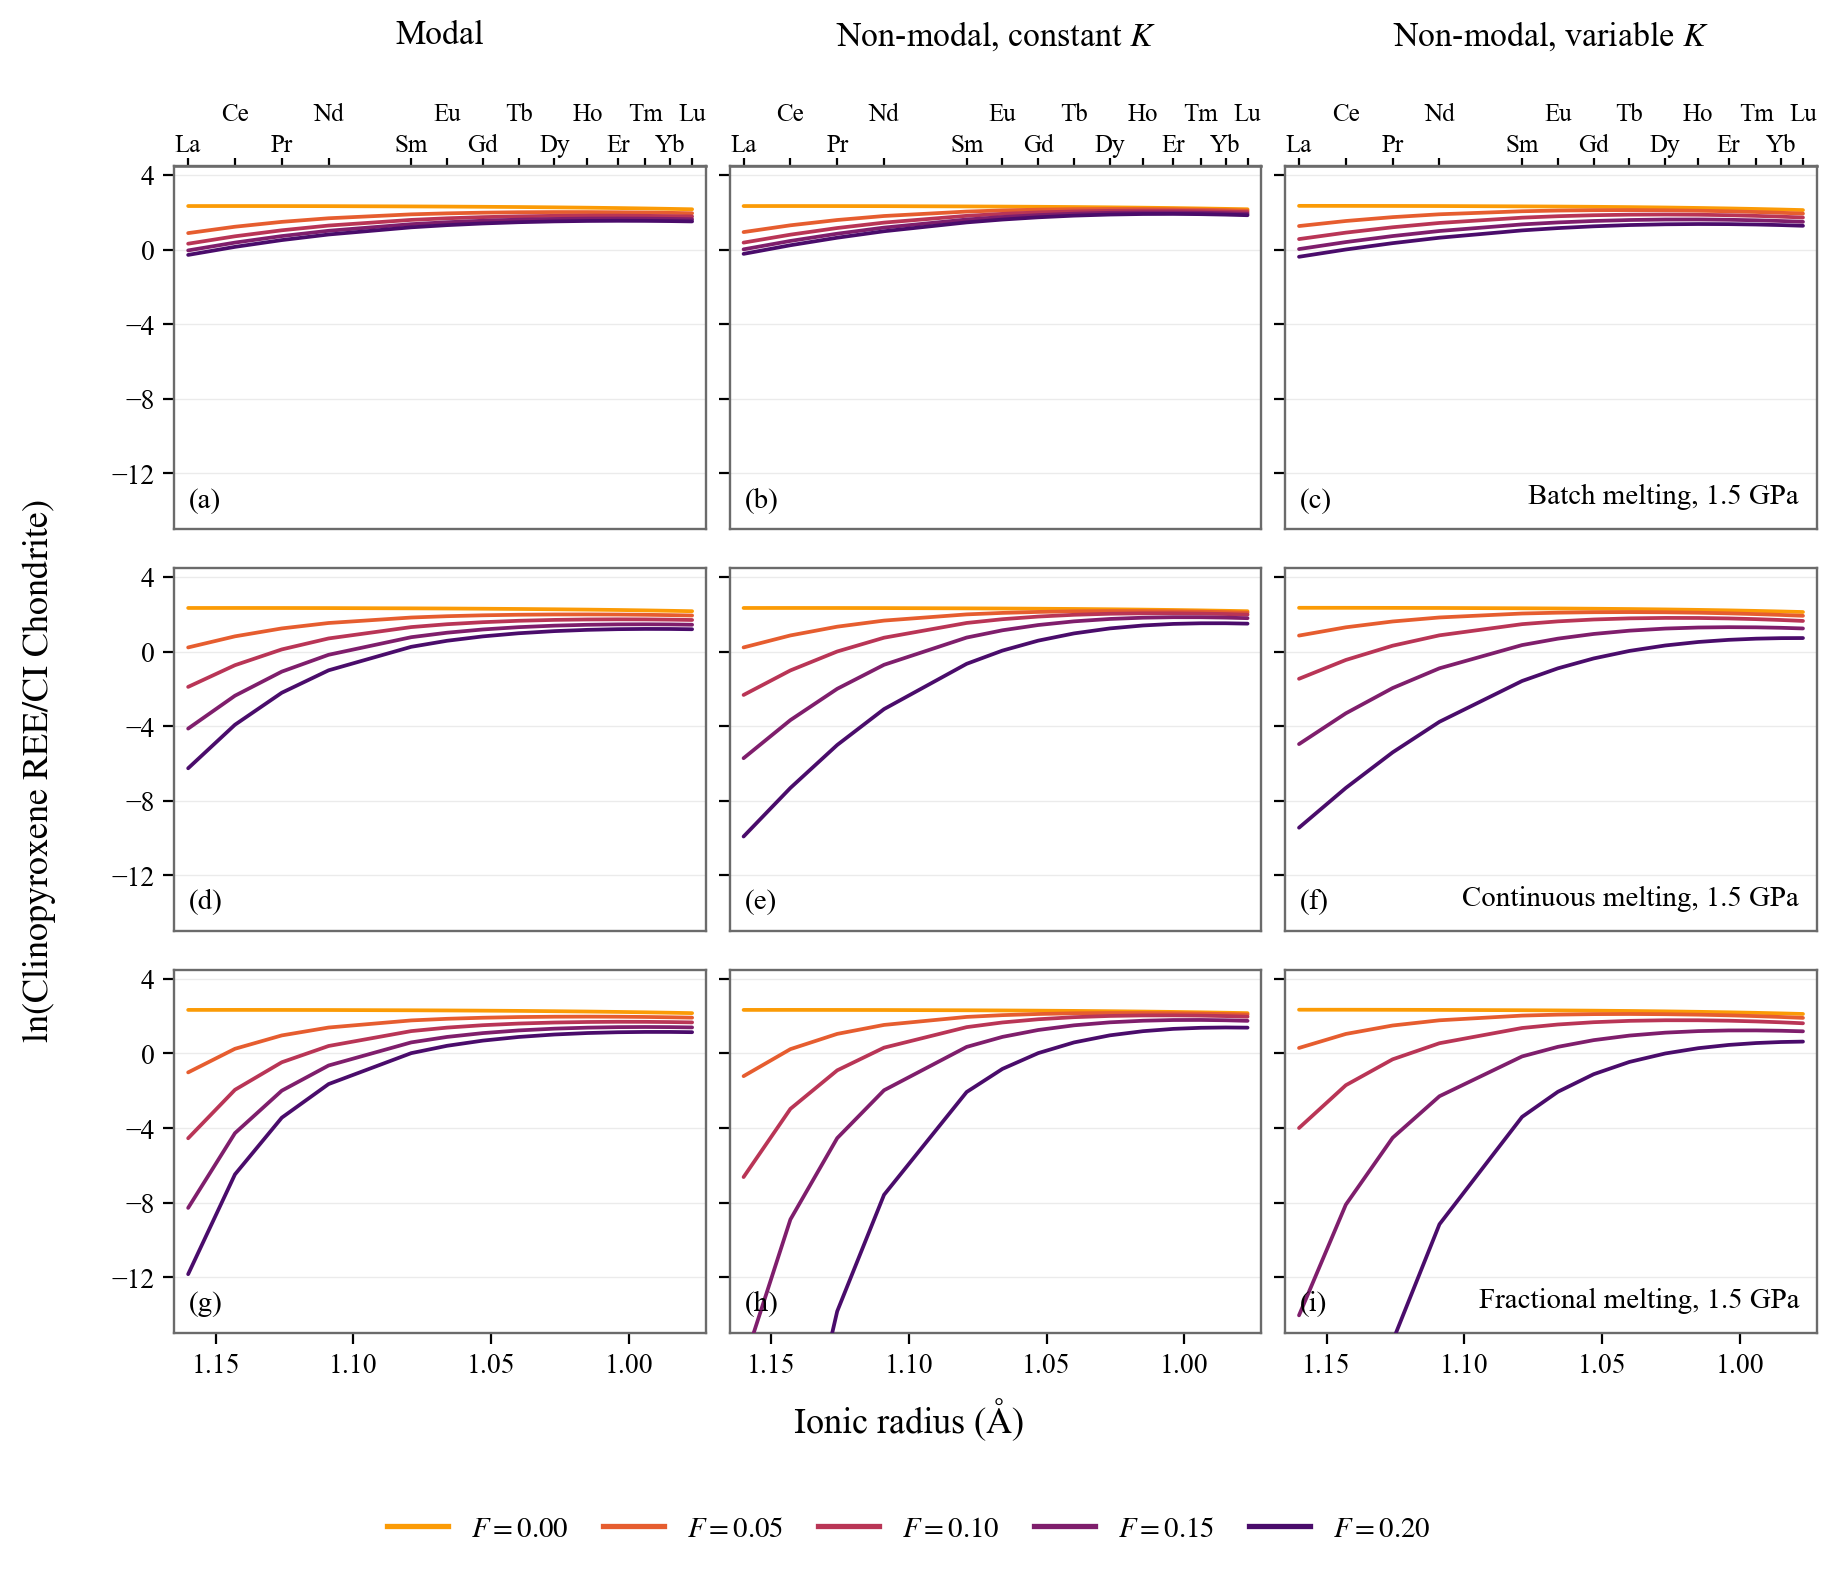

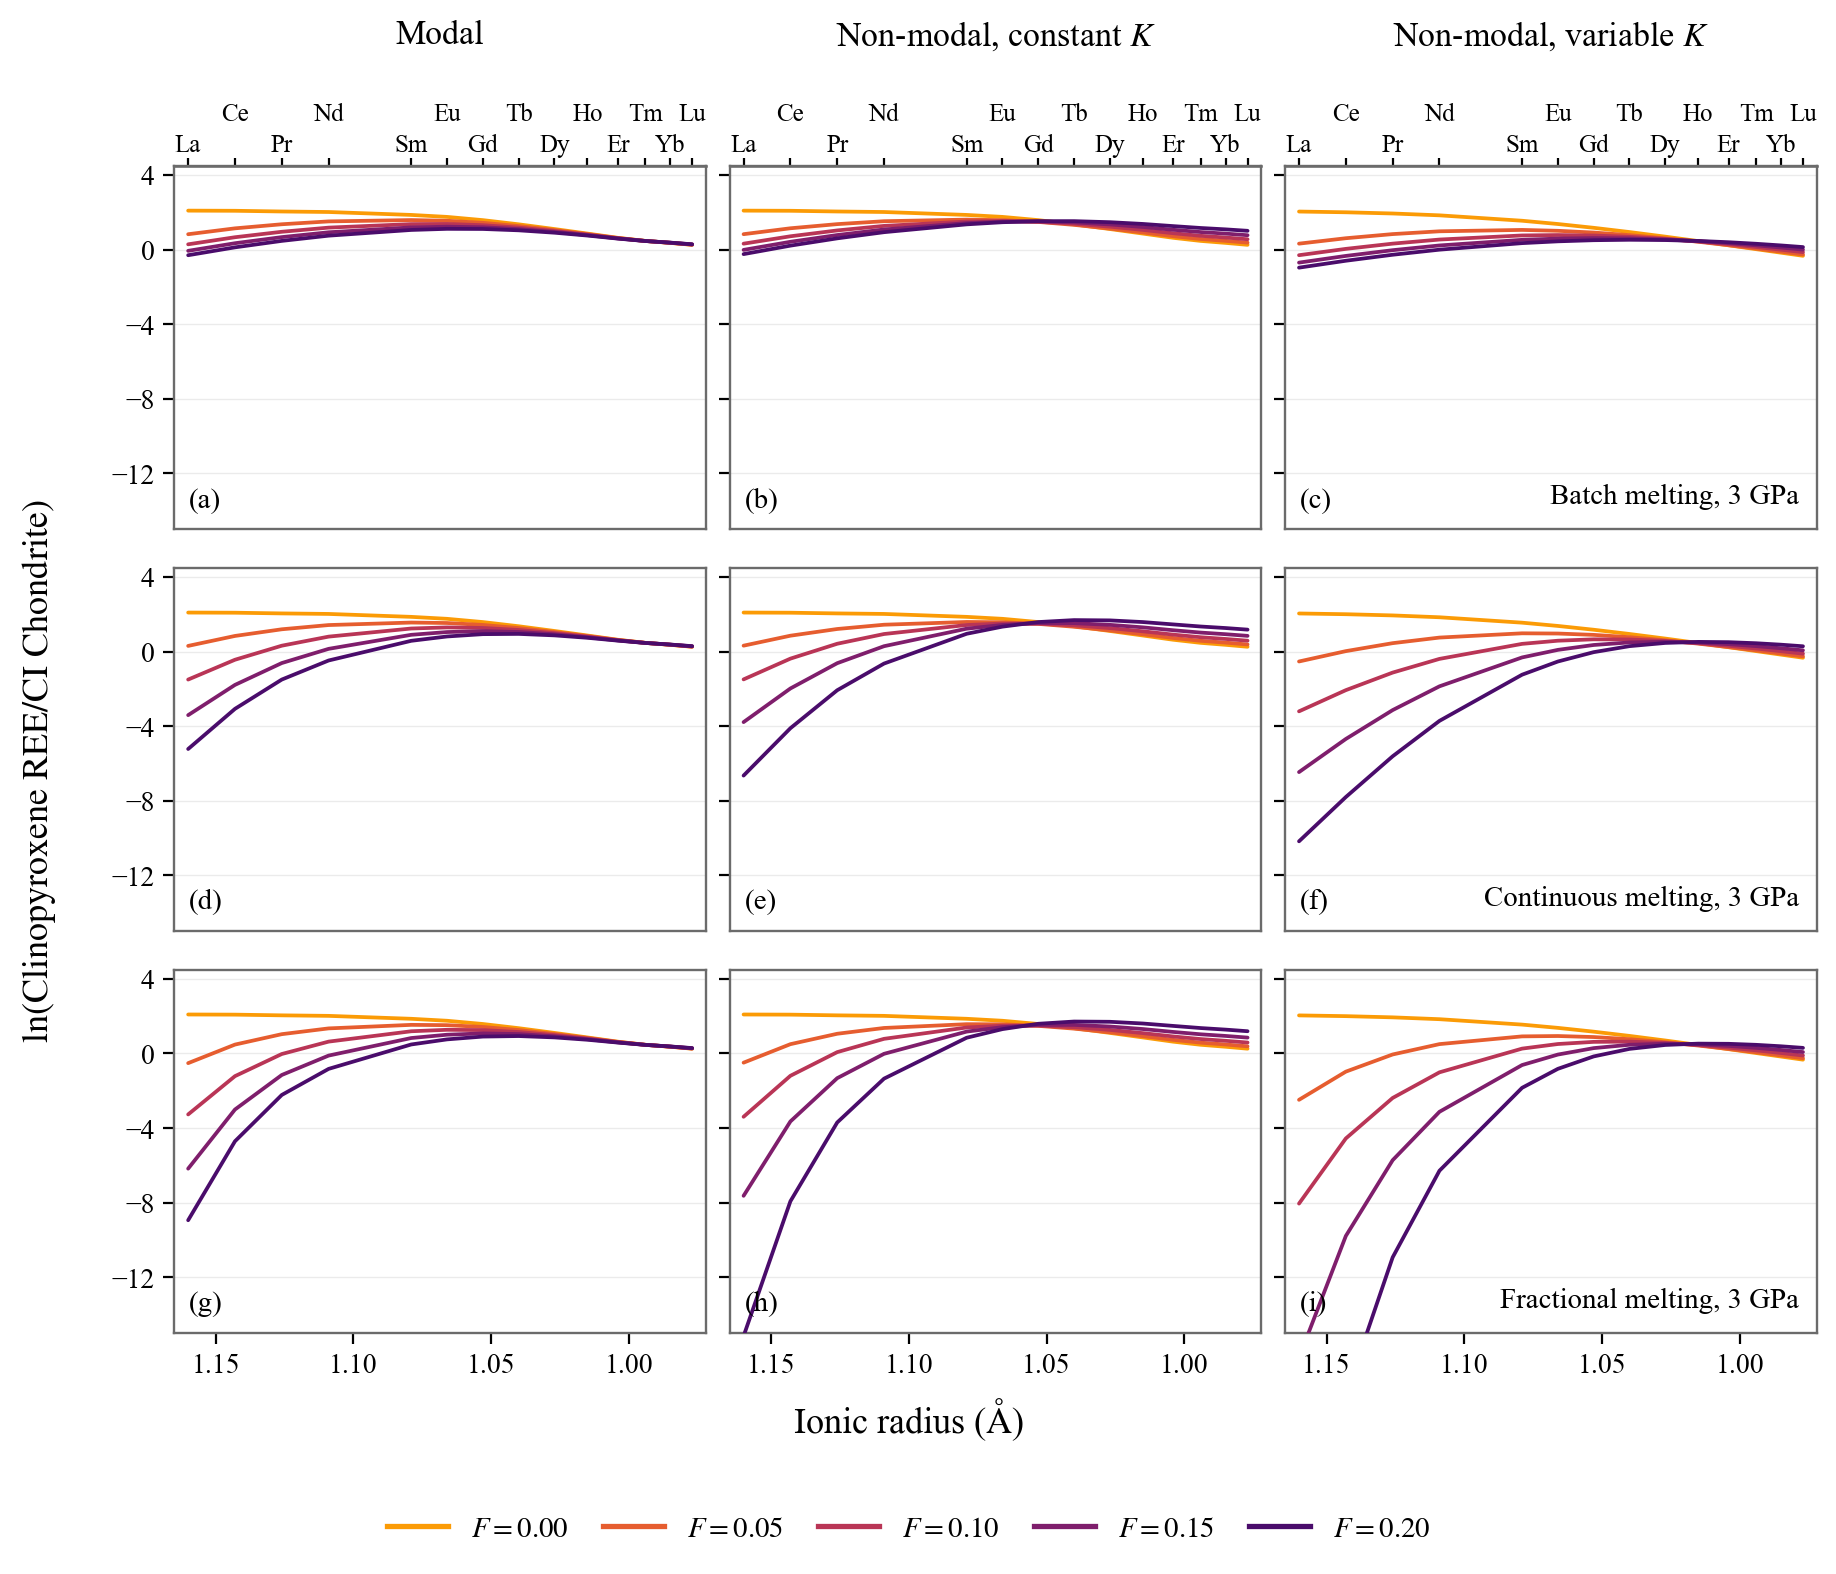

In [6]:
# Figures 4.6 and 4.7
REE_Y_MIN, REE_Y_MAX = -15.0, 4.5


def curve_colour(F, F_ref_max=0.2):
    return plt.get_cmap("inferno")(np.interp(np.clip(F, 0, F_ref_max), [0, F_ref_max], [0.78, 0.22]))


def ree_curve_ln(traj, F_target):
    idx = int(np.argmin(np.abs(traj.index.to_numpy(float) - F_target)))
    if not np.isclose(traj.index[idx], F_target, atol=0.003):
        return np.full(len(REE), np.nan)
    norm = traj.iloc[idx][REE].to_numpy(float) / CI_ARR
    with np.errstate(divide="ignore", invalid="ignore"):
        return np.where(np.isfinite(norm) & (norm > 0), np.log(norm), np.nan)


def add_ree_top_axis(ax, fontsize=9.0, low_offset=3, high_offset=14):
    secax = ax.secondary_xaxis("top")
    secax.set_xticks(RADII)
    secax.set_xticklabels([])
    secax.tick_params(axis="x", direction="out", pad=0, length=3, width=0.8)
    secax.spines["top"].set_color("0.4")
    for i, (element, radius) in enumerate(zip(REE, RADII)):
        ax.annotate(element, (radius, 1), xycoords=("data", "axes fraction"), xytext=(0, low_offset if i % 2 == 0 else high_offset),
                    textcoords="offset points", ha="center", va="bottom", fontsize=fontsize, annotation_clip=False)


def plot_ree_patterns(P):
    f_last = float(F_SHOW.max())
    columns = [("Modal", "modal"), ("Non-modal, constant $K$", "nonmodal_constant"), ("Non-modal, variable $K$", "nonmodal_variable")]
    with plt.rc_context(THESIS_RC):
        fig, axes = plt.subplots(3, 3, figsize=(9.3, 8.4), dpi=200, sharex=True, sharey=True,
                                 gridspec_kw=dict(left=0.105, right=0.988, bottom=0.165, top=0.860, wspace=0.045, hspace=0.105))
        for j, (title, _) in enumerate(columns):
            pos = axes[0, j].get_position()
            fig.text(pos.x0 + pos.width / 2, 0.947, title, ha="center", va="top", fontsize=12.2, linespacing=1.05)
        for i, style in enumerate(STYLES):
            for j, (_, run) in enumerate(columns):
                ax, traj = axes[i, j], SCENARIOS[P, style, run]
                possible = traj.index.to_numpy(float)[np.isfinite(traj[REE].to_numpy(float)).any(axis=1)]
                f_end = float(possible[-1]) if len(possible) else np.nan
                targets = [f for f in F_SHOW if np.isfinite(f_end) and f <= f_end + 1e-10]
                for f in targets:
                    vals = ree_curve_ln(traj, f)
                    if np.isfinite(vals).any():
                        ax.plot(RADII, vals, color=curve_colour(f, f_last), lw=1.35, zorder=3, solid_capstyle="round")
                if np.isfinite(f_end) and f_end < f_last - 0.003:
                    vals = ree_curve_ln(traj, f_end)
                    if np.isfinite(vals).any():
                        if not any(np.isclose(f_end, f, atol=.003) for f in targets):
                            ax.plot(RADII, vals, color=curve_colour(f_end, f_last), lw=1.35, zorder=4)
                        inside = np.flatnonzero(np.isfinite(vals) & (vals >= REE_Y_MIN + 1.3) & (vals <= REE_Y_MAX - 0.8))
                        if len(inside):
                            k = inside[len(inside) // 2]
                            ax.text(RADII[k], vals[k], rf"$F={f_end:.2f}$ cpx-out", fontsize=7.8, ha="center", va="center",
                                    color=curve_colour(f_end, f_last), zorder=8,
                                    bbox={"facecolor": "white", "edgecolor": "none", "alpha": .88, "pad": .4})
                ax.set_xlim(RADII.max() + 0.005, RADII.min() - 0.005)
                ax.set_ylim(REE_Y_MIN, REE_Y_MAX)
                ax.set_xticks(RADIUS_TICKS)
                ax.yaxis.set_major_locator(MaxNLocator(nbins=5))
                ax.grid(axis="y", color="0.92", linewidth=0.5)
                ax.tick_params(axis="both", labelsize=10.0, direction="out", pad=3)
                for spine in ax.spines.values():
                    spine.set_color("0.42")
                    spine.set_linewidth(0.85)
                if j != 0:
                    ax.tick_params(labelleft=False)
                if i != 2:
                    ax.tick_params(labelbottom=False, bottom=False)
                ax.text(0.028, 0.045, f"({string.ascii_lowercase[3 * i + j]})", transform=ax.transAxes, ha="left",
                        va="bottom", fontsize=10.4, zorder=10)
                if j == 2:
                    ax.text(0.967, 0.055, f"{STYLE_LABELS[style]}, {P:g} GPa", transform=ax.transAxes, ha="right",
                            va="bottom", fontsize=10.4, bbox={"facecolor": "white", "edgecolor": "none", "alpha": .82, "pad": 1.0})
                if i == 0:
                    add_ree_top_axis(ax, fontsize=9.0)
        fig.supylabel(r"$\ln(\mathrm{Clinopyroxene\ REE}/\mathrm{CI\ Chondrite})$", x=0.022, fontsize=13)
        fig.supxlabel(r"Ionic radius ($\mathrm{\AA}$)", y=0.100, fontsize=13)
        fig.legend(handles=[Line2D([0], [0], color=curve_colour(f, f_last), lw=1.9, label=rf"$F={f:.2f}$") for f in F_SHOW],
                   loc="lower center", bbox_to_anchor=(0.5, 0.025), ncol=len(F_SHOW), frameon=False, fontsize=10.4,
                   handlelength=2.1, columnspacing=1.2)
        save_figure(fig, f"ree_patterns_{P:g}GPa_ln", pad=0.05)


for P in PRESSURES:
    plot_ree_patterns(P)

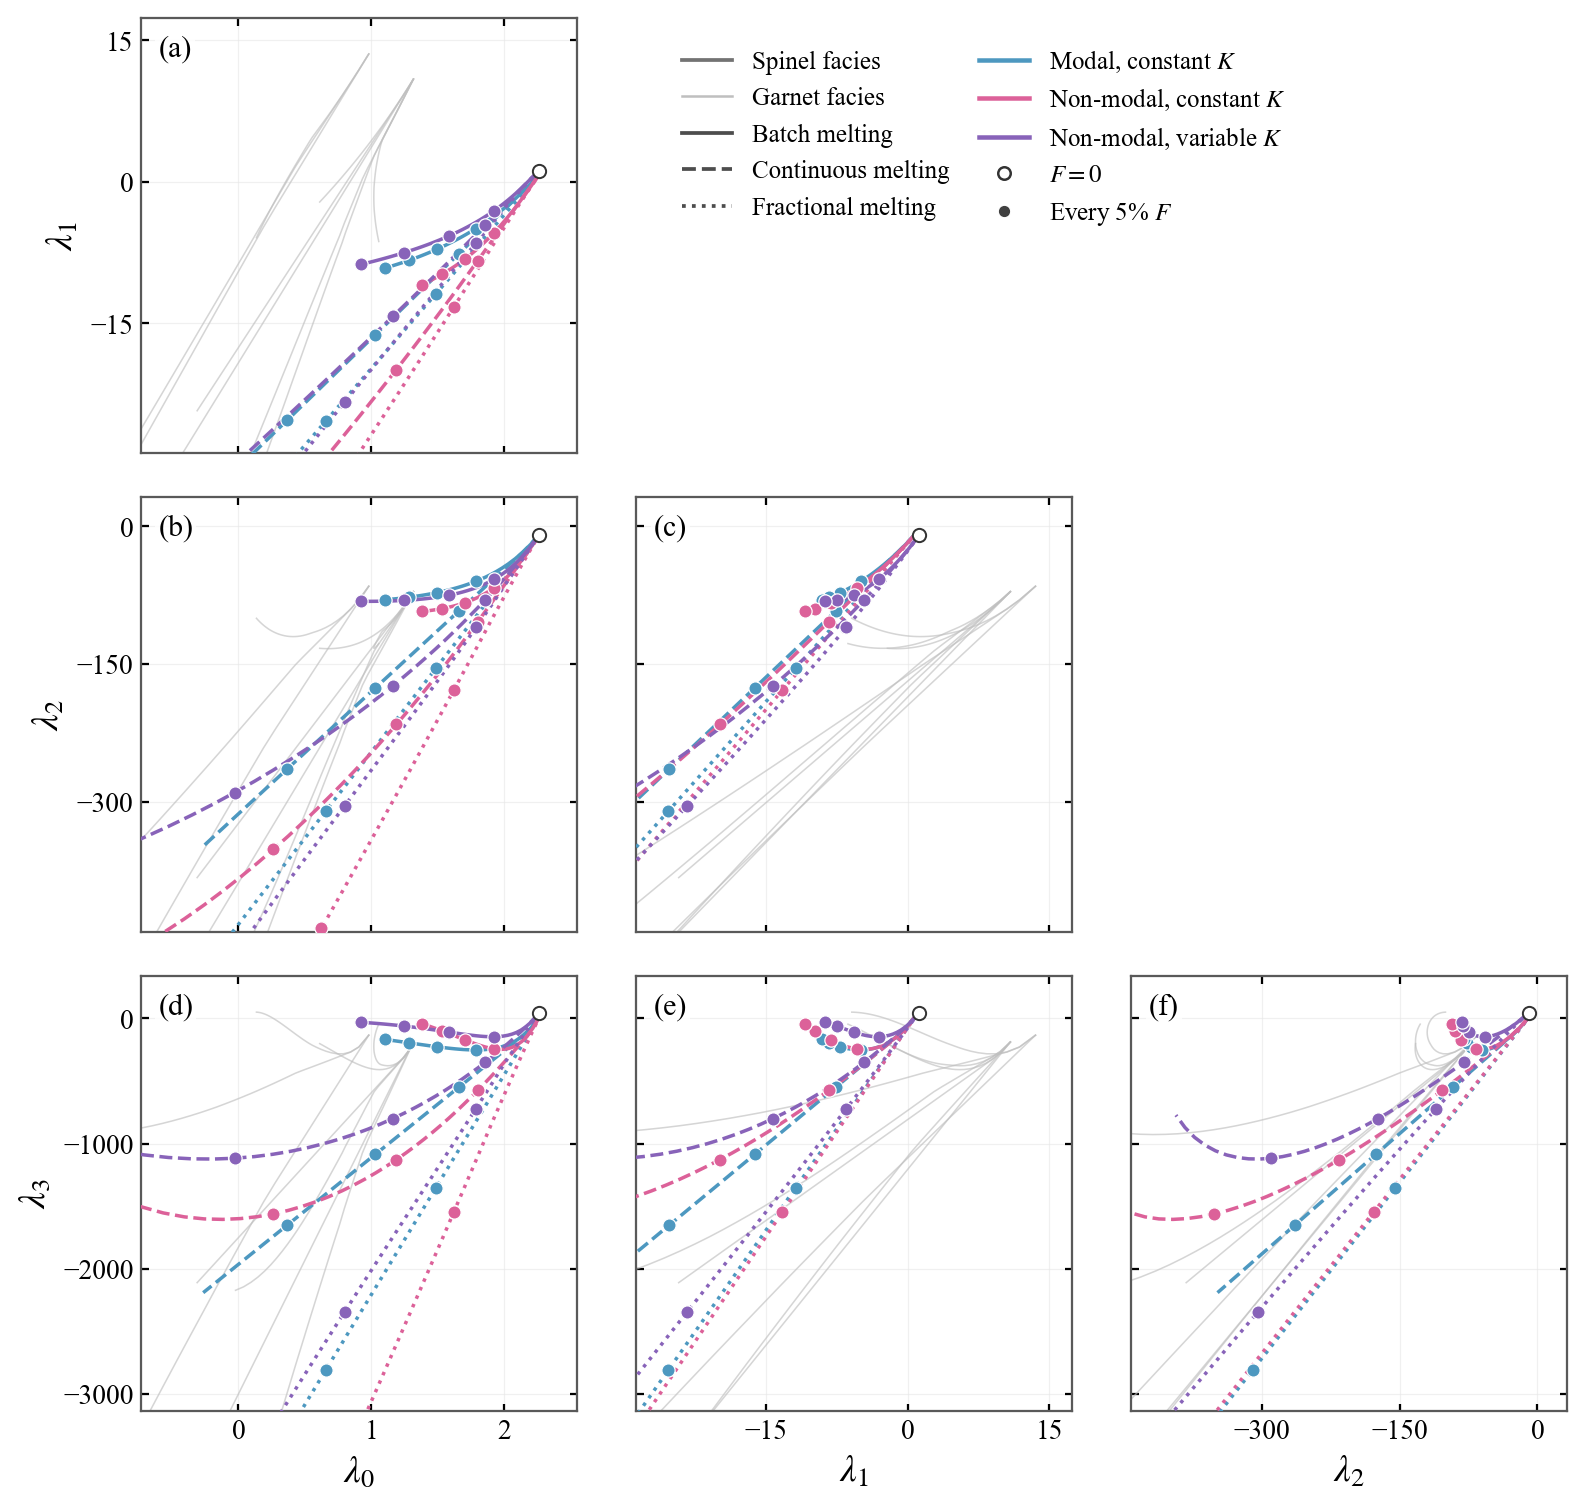

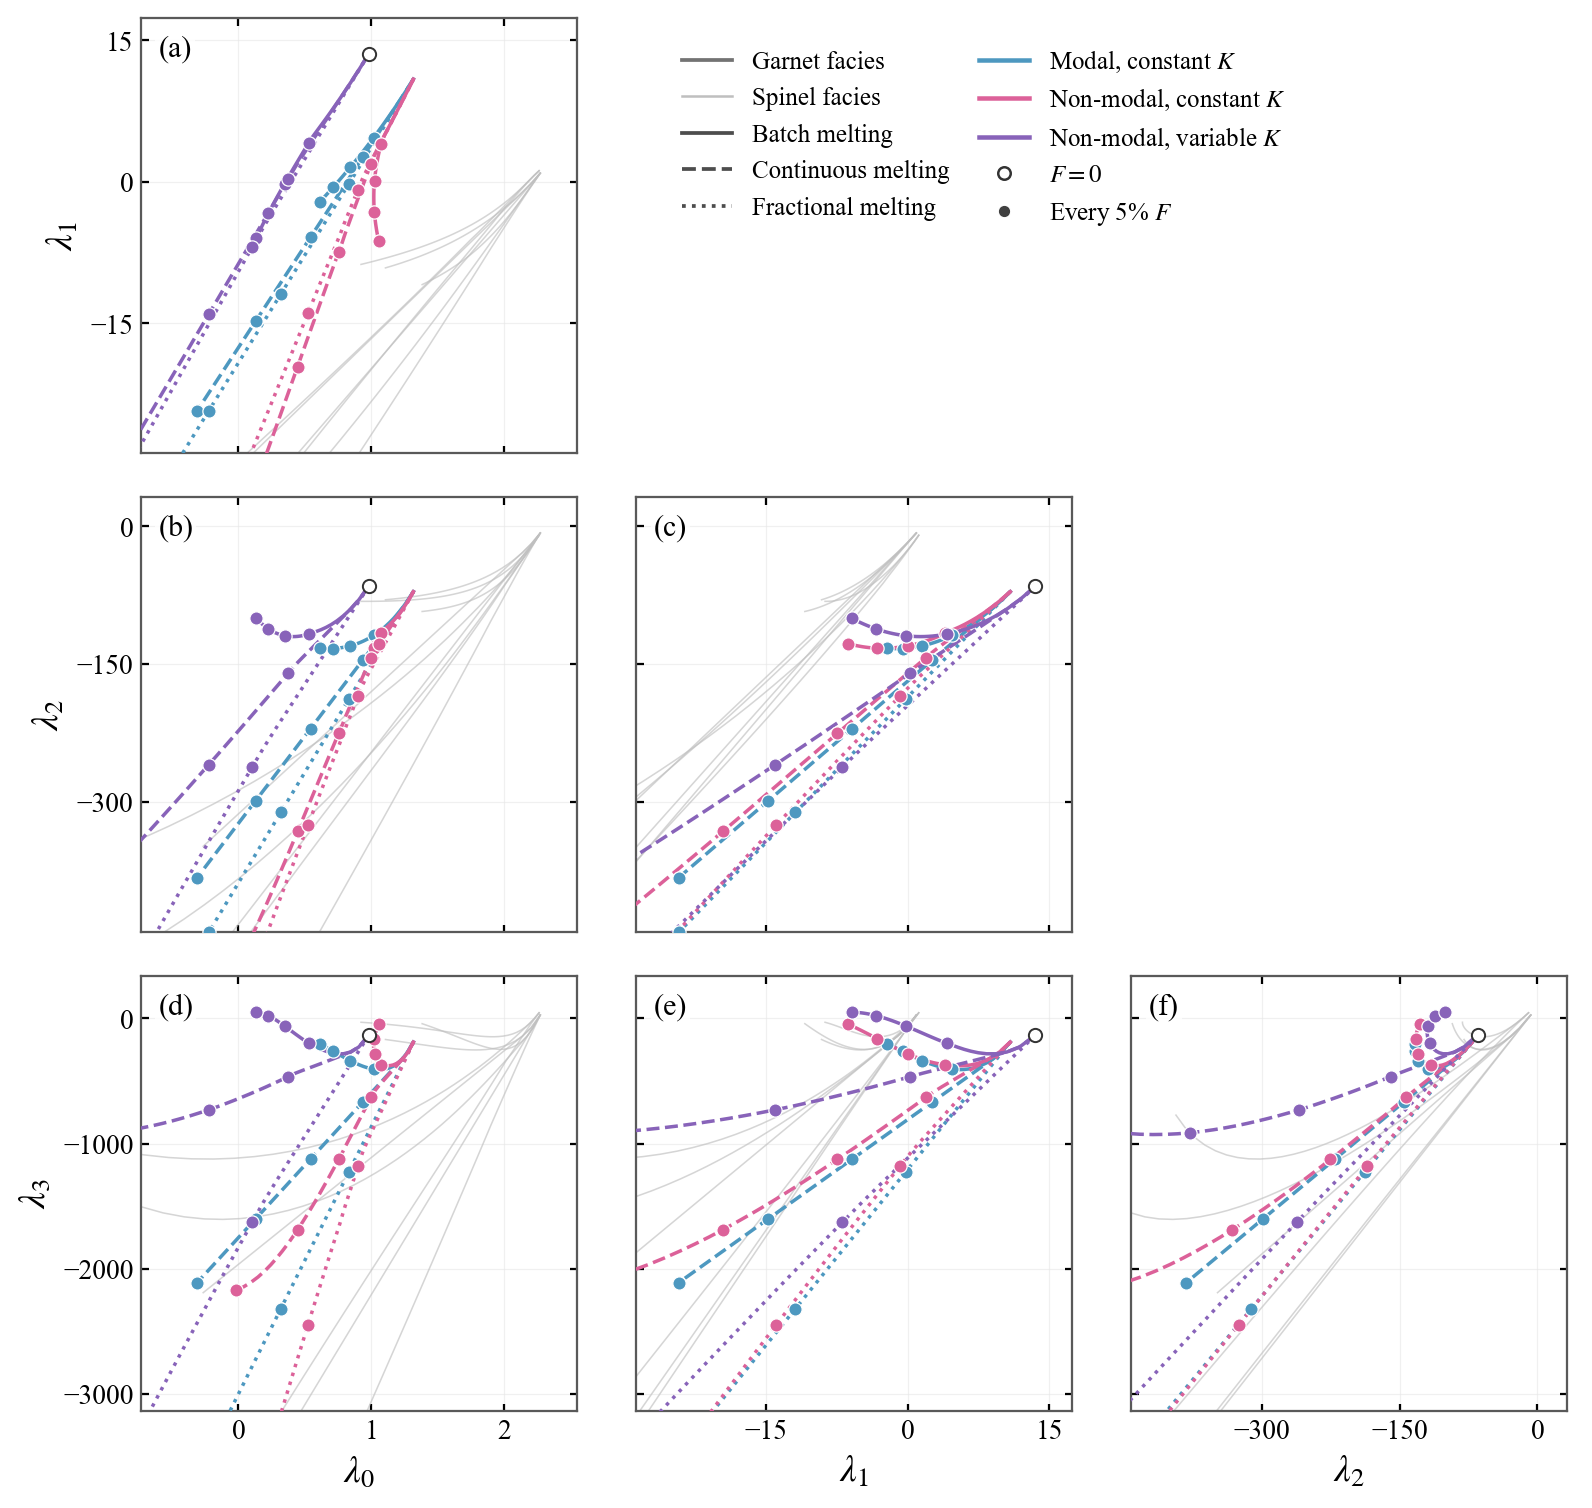

In [7]:
# Figures 4.8 and 4.9
VIEW_FMAX, F_STEP, L3_TOP_CUTOFF, GREY = 0.08, 0.05, -500, "0.75"
FACIES_LABELS = {"spinel": "Spinel facies", "garnet": "Garnet facies"}

limits = {}
visible = pd.concat([lambda_model_df[lambda_model_df.F <= VIEW_FMAX], lambda_model_df[lambda_model_df.lambda_3 >= L3_TOP_CUTOFF]])
for term in LAMBDA_TERMS:
    v = pd.to_numeric(visible[term], errors="coerce").dropna()
    pad = 0.10 * (v.max() - v.min()) if v.max() > v.min() else 0.2
    limits[term] = (v.min() - pad, v.max() + pad)


def draw_pair(ax, x, y, active):
    marks = []
    for facies in ("spinel", "garnet"):
        selected = facies == active
        m = lambda_model_df[lambda_model_df.P_GPa.isin([p for p in PRESSURES if FACIES[p] == facies])]
        for run in RUN_COLORS:
            for style in STYLES:
                t = m[(m.run == run) & (m["style"] == style)].dropna(subset=[x, y, "F"]).drop_duplicates("F").sort_values("F")
                if len(t) < 2:
                    continue
                color = RUN_COLORS[run] if selected else GREY
                ax.plot(t[x], t[y], color=color, ls=LINESTYLES[style] if selected else "-", lw=1.4 if selected else 0.62,
                        alpha=1 if selected else 0.65, zorder=5 if selected else 1)
                if selected:
                    marks.append((t, color))
        if selected:
            start = m[(m.run == "nonmodal_variable") & (m["style"] == "batch")].sort_values("F")
            if not start.empty:
                ax.scatter(start.iloc[0][x], start.iloc[0][y], s=28, facecolor="white", edgecolor="0.2", linewidth=0.8, zorder=25)
    return marks


def plot_corner(active):
    other = "garnet" if active == "spinel" else "spinel"
    with plt.rc_context({**THESIS_RC, "font.size": 12, "xtick.labelsize": 11, "ytick.labelsize": 11}):
        fig, axes = plt.subplots(3, 3, figsize=(9.2, 8.9), dpi=180)
        fig.subplots_adjust(left=0.11, right=0.98, bottom=0.10, top=0.97, wspace=0.10, hspace=0.10)
        marks = []
        for row, col in np.ndindex(3, 3):
            ax = axes[row, col]
            if col > row:
                ax.axis("off")
                continue
            x, y = f"lambda_{col}", f"lambda_{row + 1}"
            ax.set(xlim=limits[x], ylim=limits[y])
            ax.set_box_aspect(1)
            marks += [(ax, t, x, y, color) for t, color in draw_pair(ax, x, y, active)]
            ax.xaxis.set_major_locator(MaxNLocator(nbins=4))
            ax.yaxis.set_major_locator(MaxNLocator(nbins=4))
            ax.tick_params(direction="in", top=True, right=True, length=3, width=0.9, pad=3, labelsize=11,
                           labelbottom=(row == 2), labelleft=(col == 0))
            if row == 2:
                ax.set_xlabel(rf"$\lambda_{col}$", fontsize=15)
            if col == 0:
                ax.set_ylabel(rf"$\lambda_{row + 1}$", fontsize=15)
            ax.text(0.04, 0.96, f"({string.ascii_lowercase[row * (row + 1) // 2 + col]})", transform=ax.transAxes, ha="left",
                    va="top", fontsize=12, zorder=30, bbox=dict(facecolor="white", edgecolor="none", alpha=0.85, pad=1.2))
            ax.set_axisbelow(True)
            ax.grid(color="0.90", linewidth=0.5, alpha=0.6)
            for spine in ax.spines.values():
                spine.set(color="0.35", linewidth=0.9)
        for ax, t, x, y, color in marks:
            F = t.F.to_numpy(float)
            if len(F) >= 2:
                f_marks = np.arange(F_STEP, F.max() + 1e-9, F_STEP)
                f_marks = f_marks[f_marks > F.min()]
                ax.plot(np.interp(f_marks, F, t[x].to_numpy(float)), np.interp(f_marks, F, t[y].to_numpy(float)), ls="none",
                        marker="o", ms=5.3, mfc=color, mec="white", mew=0.5, zorder=20)
        handles = ([Line2D([], [], color="0.45", lw=1.5, label=FACIES_LABELS[active]),
                    Line2D([], [], color=GREY, lw=1.0, label=FACIES_LABELS[other])]
                   + [Line2D([], [], color="0.3", ls=LINESTYLES[s], lw=1.5, label=STYLE_LABELS[s]) for s in STYLES]
                   + [Line2D([], [], color=RUN_COLORS[r], lw=1.8, label=RUN_LABELS[r]) for r in RUN_COLORS]
                   + [Line2D([], [], ls="none", marker="o", mfc="white", mec="0.2", ms=5, label=r"$F=0$"),
                      Line2D([], [], ls="none", marker="o", mfc="0.25", mec="white", mew=0.5, ms=5,
                             label=rf"Every {100 * F_STEP:.0f}% $F$")])
        fig.legend(handles=handles, loc="upper left", bbox_to_anchor=(0.435, 0.957), ncol=2, frameon=False, fontsize=10,
                   handlelength=2.0, columnspacing=1.2, labelspacing=0.5, borderaxespad=0)
        save_figure(fig, f"lambda_corner_l0_l3_{active}_facies", pad=.06)


for facies in ("spinel", "garnet"):
    plot_corner(facies)

In [8]:
# Depleted residues used in Chapters 6 and 7
rows = []
for (P, style, run), traj in SCENARIOS.items():
    if run == "modal":
        continue
    path, D_mode = MODE_PATHS[P, style], RUNS[run][1]
    for F in F_GRID[F_GRID <= path["F"].max() + 1e-10]:
        mode, cpx = mode_at(P, style, float(F)), traj.loc[F].to_numpy(float)
        if mode is None or mode["Clinopyroxene"] < CPX_TOL or not np.all(np.isfinite(cpx)):
            continue
        D = D_at(P, style, float(F), D_mode)
        rows.append({"P_GPa": P, "P_kbar": P * 10, "facies": FACIES[P], "style": style, "D_mode": D_mode, "F": float(F),
                     "T_C": T_at(P, style, F) - 273.15, **{col: mode[ph] for ph, col in PHASES.items()},
                     **{ox: float(np.interp(F, path["F"], path[ox])) for ox in OXIDES},
                     **{f"{el}_residue": v for el, v in zip(REE, cpx * bulk_D(mode, D) / D["Clinopyroxene"])},
                     **{f"{el}_cpx": v for el, v in zip(REE, cpx)},
                     **dict(zip(LAMBDA_TERMS, model_lambda(cpx)))})
pd.DataFrame(rows).to_csv(DATA_FOLDER / "metasomatism_starting_states_runs.csv", index=False)